In [1]:
import pandas as pd
import os

In [46]:
import numpy as np
path = r"C:\Users\wklee\Desktop\WKLee\FBA\Capstone\fba-capstone\data\HayashiYoshidaTicker_Threshold"

def get_threshold_pathlist(threshold):
    path_list = os.listdir(path)
    thresholds_list = np.array([int(path.split('_CORR')[0].split('-')[1]) for path in path_list])
    path_arr = np.array(path_list)

    threshhold_cond_pathlist = path_arr[thresholds_list == threshold]
    
    threshhold_cond_pathlist = [path for path in threshhold_cond_pathlist if path.split('_')[2].split('-')[1] == 'spot']
    threshhold_cond_pathlist = [path for path in threshhold_cond_pathlist if path.split('_')[3].split('-')[1] == 'future']
    
    # if llr high, future lead.
    return threshhold_cond_pathlist

In [47]:
def read_txt(path):
    with open(path) as f:
        data = [l.strip().split(",") for l in f.readlines()]
        df = pd.DataFrame(data, columns=["lag", "corr"])
        df['corr'] = df['corr'].astype(float)
        return df.set_index('lag')

def extract_corr(path):
    df = read_txt(path)
    maxcorr = df['corr'].max()
    llr = df[df.index.astype(int) < 0]['corr'].sum() / df[df.index.astype(int) > 0]['corr'].sum()
    return [maxcorr, llr]

In [48]:
def get_threshold_df(threshold):
    data_list = []
    pathlist = get_threshold_pathlist(threshold)
    for thpath in pathlist:    
        data = extract_corr(os.path.join(path, thpath))
        data_list.append(data)
    return pd.DataFrame(data_list, columns=['maxcor', 'llr'])

In [49]:
df1 = get_threshold_df(1)
df2 = get_threshold_df(2)
df3 = get_threshold_df(3)
df4 = get_threshold_df(4)

C:\Users\wklee\AppData\Local\Temp\ipykernel_25152\3382656796.py:11: RuntimeWarning: invalid value encountered in scalar divide
  llr = df[df.index.astype(int) < 0]['corr'].sum() / df[df.index.astype(int) > 0]['corr'].sum()
C:\Users\wklee\AppData\Local\Temp\ipykernel_25152\3382656796.py:11: RuntimeWarning: invalid value encountered in scalar divide
  llr = df[df.index.astype(int) < 0]['corr'].sum() / df[df.index.astype(int) > 0]['corr'].sum()
C:\Users\wklee\AppData\Local\Temp\ipykernel_25152\3382656796.py:11: RuntimeWarning: invalid value encountered in scalar divide
  llr = df[df.index.astype(int) < 0]['corr'].sum() / df[df.index.astype(int) > 0]['corr'].sum()
C:\Users\wklee\AppData\Local\Temp\ipykernel_25152\3382656796.py:11: RuntimeWarning: invalid value encountered in scalar divide
  llr = df[df.index.astype(int) < 0]['corr'].sum() / df[df.index.astype(int) > 0]['corr'].sum()
C:\Users\wklee\AppData\Local\Temp\ipykernel_25152\3382656796.py:11: RuntimeWarning: invalid value encountere

In [53]:
df3

,maxcor,llr
0,0.144166,0.805163
1,0.173629,0.904141
2,0.259341,1.105913
3,0.370978,1.213121
4,0.028245,0.751047
5,NaN,NaN
6,NaN,NaN
7,-0.006086,0.820098
8,0.260970,0.949063
9,0.389730,0.992410


Text(0.5, 1.0, "LLR of each pairs which indicate 'Future leads Spot'. \n x axis: threshold return. (10^(-4))")

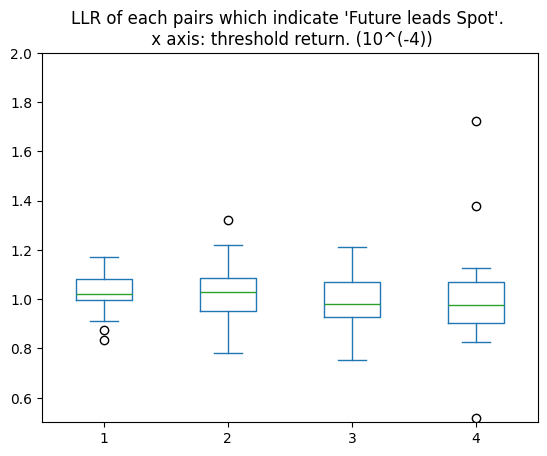

In [56]:
import matplotlib.pyplot as plt 

maxcor_df = pd.concat([df1['llr'], df2['llr'], df3['llr'], df4['llr']], axis=1)
maxcor_df.columns = range(1, 5)
maxcor_df.plot(kind='box', ylim=(0.5, 2))
plt.title("LLR of each pairs which indicate 'Future leads Spot'. \n x axis: threshold return. (10^(-4))")